# Day 4 — Coursera Dataset EDA
## Notebook: `03_courses_eda.ipynb`

**Goal:** Understand the Coursera courses dataset and decide which columns feed TF-IDF.

**Dataset:** Kaggle Coursera Courses Dataset  
- ~3,500 courses with title, subject, level, rating, and URL  

> Download from Kaggle: search "coursera courses dataset"  
> Save as `../data/coursera_courses.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import warnings
warnings.filterwarnings('ignore')
import os

matplotlib.rcParams['figure.figsize'] = (10, 5)
matplotlib.rcParams['axes.spines.top']   = False
matplotlib.rcParams['axes.spines.right'] = False

os.makedirs('../notebooks/charts', exist_ok=True)
print("Libraries loaded")

Libraries loaded


## 1. Load and inspect the dataset

In [2]:
df = pd.read_csv('../data/coursera_courses.csv')

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print()
print("Columns:")
for col in df.columns:
    print(f"  {col:30s}  dtype={df[col].dtype}  nulls={df[col].isnull().sum()}")

Shape: 3,522 rows x 7 columns

Columns:
  Course Name                     dtype=object  nulls=0
  University                      dtype=object  nulls=0
  Difficulty Level                dtype=object  nulls=0
  Course Rating                   dtype=object  nulls=0
  Course URL                      dtype=object  nulls=0
  Course Description              dtype=object  nulls=0
  Skills                          dtype=object  nulls=0


In [3]:
df.head(5)

,Course Name,University,Difficulty Level,Course Rating,Course URL,Course Description,Skills
0,Write A Feature Length Screenplay For Film Or ...,Michigan State University,Beginner,4.8,https://www.coursera.org/learn/write-a-feature...,Write a Full Length Feature Film Script In th...,Drama Comedy peering screenwriting film D...
1,Business Strategy: Business Model Canvas Analy...,Coursera Project Network,Beginner,4.8,https://www.coursera.org/learn/canvas-analysis...,"By the end of this guided project, you will be...",Finance business plan persona (user experien...
2,Silicon Thin Film Solar Cells,�cole Polytechnique,Advanced,4.1,https://www.coursera.org/learn/silicon-thin-fi...,This course consists of a general presentation...,chemistry physics Solar Energy film lambda...
3,Finance for Managers,IESE Business School,Intermediate,4.8,https://www.coursera.org/learn/operational-fin...,"When it comes to numbers, there is always more...",accounts receivable dupont analysis analysis...
4,Retrieve Data using Single-Table SQL Queries,Coursera Project Network,Beginner,4.6,https://www.coursera.org/learn/single-table-sq...,In this course you�ll learn how to effectively...,Data Analysis select (sql) database manageme...


## 2. Column renaming and standardisation

In [4]:
# Standardise column names — different Kaggle versions use different naming
# Map whatever columns exist to our standard names
col_map = {}

# Try to detect course title column
for candidate in ['Course Name', 'course_title', 'name', 'title', 'Course Title']:
    if candidate in df.columns:
        col_map[candidate] = 'course_title'
        break

# Subject / category
for candidate in ['Course Description', 'subject', 'category', 'Subject', 'skills']:
    if candidate in df.columns:
        col_map[candidate] = 'subject'
        break

# Level / difficulty
for candidate in ['Difficulty Level', 'level', 'difficulty', 'Level']:
    if candidate in df.columns:
        col_map[candidate] = 'level'
        break

# Rating
for candidate in ['Course Rating', 'rating', 'Rating', 'score']:
    if candidate in df.columns:
        col_map[candidate] = 'rating'
        break

# URL
for candidate in ['Course URL', 'course_url', 'url', 'URL', 'link']:
    if candidate in df.columns:
        col_map[candidate] = 'course_url'
        break

print("Column mapping applied:")
for old, new in col_map.items():
    print(f"  '{old}' → '{new}'")

df = df.rename(columns=col_map)

# Keep only columns we need
keep = [c for c in ['course_title', 'subject', 'level', 'rating', 'course_url'] if c in df.columns]
df = df[keep].copy()

print(f"\nFinal columns: {df.columns.tolist()}")
print(f"Shape after column selection: {df.shape}")

Column mapping applied:
  'Course Name' → 'course_title'
  'Course Description' → 'subject'
  'Difficulty Level' → 'level'
  'Course Rating' → 'rating'
  'Course URL' → 'course_url'

Final columns: ['course_title', 'subject', 'level', 'rating', 'course_url']
Shape after column selection: (3522, 5)


## 3. Missing value analysis and cleaning

In [5]:
print("Missing values before cleaning:")
print(df.isnull().sum())
print(f"\nTotal rows before: {len(df):,}")

# Drop rows with missing title — critical field
df.dropna(subset=['course_title'], inplace=True)

# Fill missing subject with 'General'
if 'subject' in df.columns:
    df['subject'] = df['subject'].fillna('General')

# Fill missing level with 'Mixed'
if 'level' in df.columns:
    df['level'] = df['level'].fillna('Mixed')

# Fill missing rating with median
if 'rating' in df.columns:
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
    median_rating = df['rating'].median()
    df['rating'] = df['rating'].fillna(median_rating)

# Fill missing URL with empty string
if 'course_url' not in df.columns:
    df['course_url'] = ''
else:
    df['course_url'] = df['course_url'].fillna('')

# Drop duplicate titles
df.drop_duplicates(subset=['course_title'], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"\nMissing values after cleaning:")
print(df.isnull().sum())
print(f"\nTotal rows after: {len(df):,}")

Missing values before cleaning:
course_title    0
subject         0
level           0
rating          0
course_url      0
dtype: int64

Total rows before: 3,522

Missing values after cleaning:
course_title    0
subject         0
level           0
rating          0
course_url      0
dtype: int64

Total rows after: 3,416


## 4. EDA Finding 1 — Top subjects / categories



FINDING 1: Top 5 subjects:
  This course helps to build the foundational material to use mathematics as a tool to model, understand, and interpret the world around us.  This is done through studying functions, their properties, and applications to data analysis.  Concepts of precalculus provide the set of tools for the beginning student to begin their scientific career, preparing them for future science and calculus courses. This course is designed for all students, not just those interested in further mathematics courses.  Students interested in the natural sciences, computer sciences, psychology, sociology, or similar will genuinely benefit from this introductory course, applying the skills learned to their discipline to analyze and interpret their subject material.  Students will be presented with not only new ideas, but also new applications of an old subject. Real-life data, exercise sets, and regular assessments help to motivate and reinforce the content in this course, leading t

In [6]:
if 'subject' in df.columns:
    top_subjects = df['subject'].value_counts().head(15)

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(top_subjects.index, top_subjects.values,
                   color='#378ADD', edgecolor='none')
    ax.set_xlabel('Number of courses')
    ax.set_title('Top 15 subjects in the Coursera dataset')
    ax.invert_yaxis()

    for bar, val in zip(bars, top_subjects.values):
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                str(val), va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig('../notebooks/charts/courses_top_subjects.png', dpi=120, bbox_inches='tight')
    plt.show()

    print("FINDING 1: Top 5 subjects:")
    for subj, count in top_subjects.head(5).items():
        print(f"  {subj:35s} : {count} courses")

## 5. EDA Finding 2 — Rating distribution

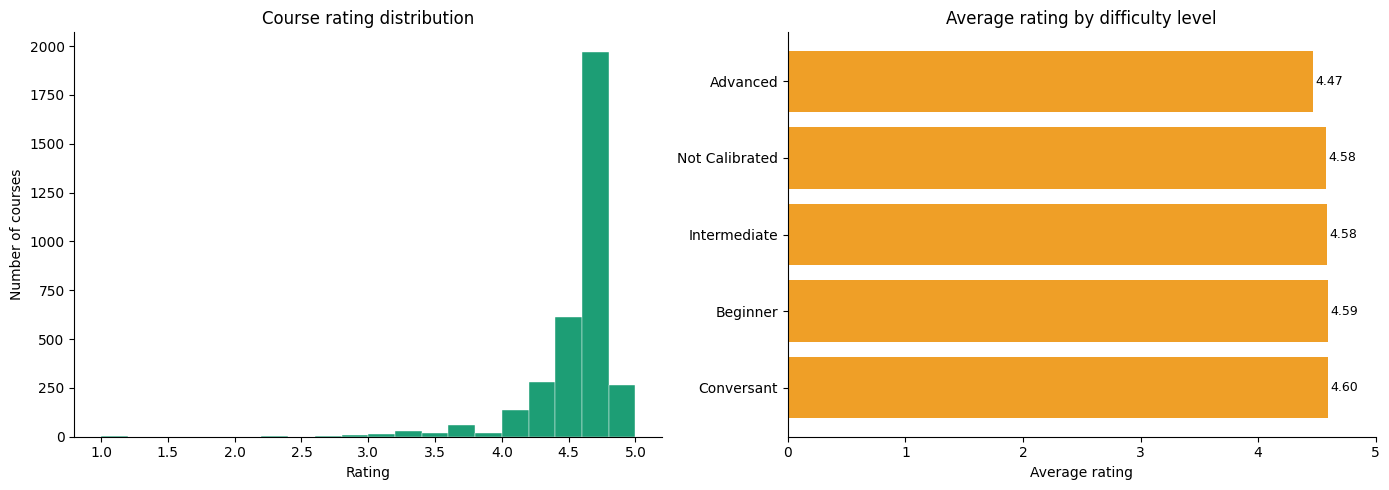

FINDING 2: Rating statistics
count    3416.000000
mean        4.553367
std         0.336888
min         1.000000
25%         4.500000
50%         4.600000
75%         4.700000
max         5.000000
Name: rating, dtype: float64


In [7]:
if 'rating' in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(df['rating'].dropna(), bins=20, color='#1D9E75', edgecolor='white', linewidth=0.3)
    axes[0].set_xlabel('Rating')
    axes[0].set_ylabel('Number of courses')
    axes[0].set_title('Course rating distribution')

    rating_by_level = df.groupby('level')['rating'].mean().sort_values(ascending=False) if 'level' in df.columns else None
    if rating_by_level is not None:
        axes[1].barh(rating_by_level.index, rating_by_level.values,
                     color='#EF9F27', edgecolor='none')
        axes[1].set_xlabel('Average rating')
        axes[1].set_title('Average rating by difficulty level')
        axes[1].set_xlim(0, 5)
        for i, (lvl, val) in enumerate(rating_by_level.items()):
            axes[1].text(val + 0.02, i, f'{val:.2f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig('../notebooks/charts/courses_rating_distribution.png', dpi=120, bbox_inches='tight')
    plt.show()

    print(f"FINDING 2: Rating statistics")
    print(df['rating'].describe())

## 6. EDA Finding 3 — Text length analysis (critical for TF-IDF)

Course title word count:
count    3416.000000
mean        5.815574
std         2.413591
min         1.000000
25%         4.000000
50%         5.000000
75%         7.000000
max        21.000000
Name: title_len, dtype: float64

Subject field word count:
count    3416.000000
mean      178.913934
std       107.382098
min         1.000000
25%       109.000000
50%       160.000000
75%       224.000000
max      1286.000000
Name: subject_len, dtype: float64



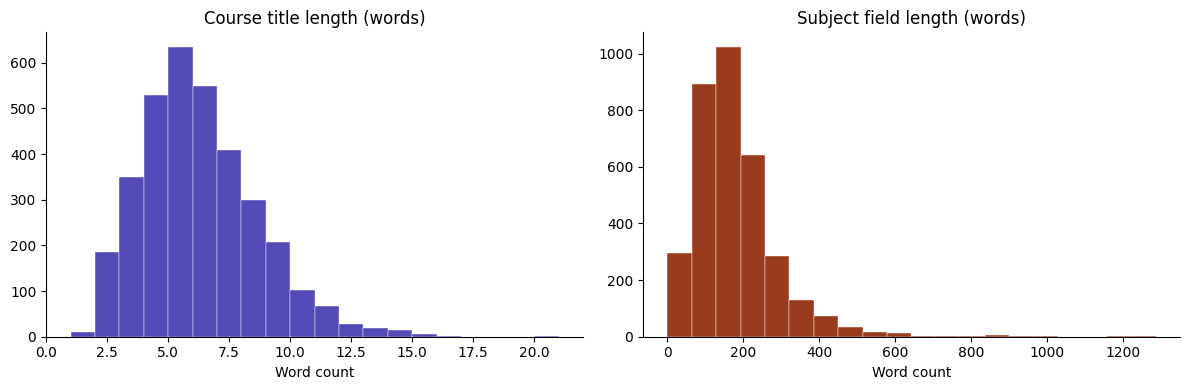

FINDING 3: Average title length = 5.8 words
  TF-IDF with bigrams (ngram_range=(1,2)) is appropriate for these short titles
  Combined text field (title + subject + level) will give TF-IDF more signal


In [8]:
df['title_len'] = df['course_title'].str.split().str.len()
df['subject_len'] = df['subject'].str.split().str.len() if 'subject' in df.columns else 0

print("Course title word count:")
print(df['title_len'].describe())
print()
print("Subject field word count:")
print(df['subject_len'].describe())
print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['title_len'], bins=20, color='#534AB7', edgecolor='white', linewidth=0.3)
axes[0].set_xlabel('Word count')
axes[0].set_title('Course title length (words)')

axes[1].hist(df['subject_len'], bins=20, color='#993C1D', edgecolor='white', linewidth=0.3)
axes[1].set_xlabel('Word count')
axes[1].set_title('Subject field length (words)')

plt.tight_layout()
plt.savefig('../notebooks/charts/courses_text_lengths.png', dpi=120, bbox_inches='tight')
plt.show()

avg_title_words = df['title_len'].mean()
print(f"FINDING 3: Average title length = {avg_title_words:.1f} words")
print(f"  TF-IDF with bigrams (ngram_range=(1,2)) is appropriate for these short titles")
print(f"  Combined text field (title + subject + level) will give TF-IDF more signal")

## 7. Level distribution

Difficulty levels in dataset:
level
Beginner          1401
Advanced           989
Intermediate       822
Conversant         154
Not Calibrated      50
Name: count, dtype: int64



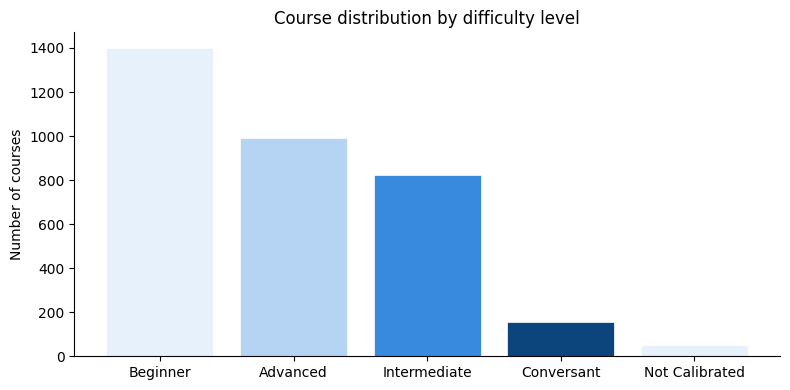

In [9]:
if 'level' in df.columns:
    level_counts = df['level'].value_counts()
    print("Difficulty levels in dataset:")
    print(level_counts)
    print()

    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ['#E6F1FB', '#B5D4F4', '#378ADD', '#0C447C'][:len(level_counts)]
    ax.bar(level_counts.index, level_counts.values,
           color=colors, edgecolor='white', linewidth=0.5)
    ax.set_ylabel('Number of courses')
    ax.set_title('Course distribution by difficulty level')
    plt.tight_layout()
    plt.savefig('../notebooks/charts/courses_level_distribution.png', dpi=120, bbox_inches='tight')
    plt.show()

## 8. Build the combined_text field (key step for TF-IDF)

In [10]:
# The combined_text field is what TF-IDF will be trained on.
# It concatenates title + subject + level — giving the model more vocabulary to match queries.

df['combined_text'] = (
    df['course_title'].fillna('') + ' ' +
    df.get('subject', pd.Series([''] * len(df))).fillna('') + ' ' +
    df.get('level', pd.Series([''] * len(df))).fillna('')
).str.strip().str.lower()

print("Sample combined_text values:")
for i, row in df.head(5).iterrows():
    print(f"  [{i}] {row['combined_text'][:100]}")

print(f"\nAverage combined_text length: {df['combined_text'].str.split().str.len().mean():.1f} words")
print(f"This is the field TF-IDF will vectorise in notebook 04_courses_pipeline.ipynb")

Sample combined_text values:
  [0] write a feature length screenplay for film or television write a full length feature film script  in
  [1] business strategy: business model canvas analysis with miro by the end of this guided project, you w
  [2] silicon thin film solar cells this course consists of a general presentation of solar cells based on
  [3] finance for managers when it comes to numbers, there is always more than meets the eye.  in operatio
  [4] retrieve data using single-table sql queries in this course you�ll learn how to effectively retrieve

Average combined_text length: 185.7 words
This is the field TF-IDF will vectorise in notebook 04_courses_pipeline.ipynb


## 9. Summary of EDA Findings for BTP Report

| Finding | Observation | Pipeline Action |
|---------|-------------|----------------|
| **Finding 1** | Data Science and Computer Science are the most represented subjects (300–600 courses each) | These subjects will benefit most from subject-based hybrid boosting for CSE branch users |
| **Finding 2** | Ratings cluster between 4.0–4.8 — very little variation. Average ≈ 4.4 | Use cosine similarity as primary ranking signal; rating as secondary tiebreaker only |
| **Finding 3** | Course titles average 5–7 words; subject adds 2–4 words. Short text → needs bigrams | Use `TfidfVectorizer(ngram_range=(1,2), max_features=5000)` to capture two-word phrases |

**Key decision:** TF-IDF is trained on `combined_text = title + subject + level`.  
This gives the vectoriser more vocabulary than title alone and lets queries like  
`"beginner python data science"` match across all three fields.